# Assignment 2 — Reproducible Data Pipelines & Tabular ML

**Student:** MASHAL KHAN  
**Roll No:** TRN-2026-000349  
**Date:** 20 November 2026  

---

This notebook walks through all three parts of Assignment 2 interactively:

| Part | Topic | Weight |
|------|-------|--------|
| A | Data Inspection, Cleaning, Validation & Analysis | 35% |
| B | Tabular ML with scikit-learn Pipelines | 40% |
| C | System Design & Engineering Extras | 25% |

> **Dataset:** Pakistan Air Quality 2024 — 52,704 rows × 13 columns  
> **Source:** Open-Meteo / ECMWF CAMS (CC BY 4.0)  
> **Cities:** Lahore, Karachi, Islamabad, Faisalabad, Multan, Peshawar

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..'))   # so 'src' is importable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import sqlite3, json, time
from pathlib import Path

matplotlib.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid', palette='muted')
print('All imports OK')

All imports OK


---
## Part A — Data Inspection, Cleaning & Analysis

### A1 · Load & Inspect Raw Data

In [2]:
RAW_CSV = Path('../data/raw/pakistan_air_quality_2024.csv')
df_raw = pd.read_csv(RAW_CSV)

print(f'Shape: {df_raw.shape}')
print(f'\nColumns: {list(df_raw.columns)}')
print(f'\nDtypes:\n{df_raw.dtypes}')

Shape: (52704, 13)

Columns: ['timestamp', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'dust', 'uv_index', 'european_aqi', 'city', 'latitude', 'longitude']

Dtypes:
timestamp               str
pm10                float64
pm2_5               float64
carbon_monoxide     float64
nitrogen_dioxide    float64
sulphur_dioxide     float64
ozone               float64
dust                float64
uv_index            float64
european_aqi          int64
city                    str
latitude            float64
longitude           float64
dtype: object


In [3]:
df_raw.head()

,timestamp,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,dust,uv_index,european_aqi,city,latitude,longitude
0,2024-01-01T00:00,375.3,260.8,4925.0,154.8,51.5,11.0,3.0,0.0,148,Lahore,31.5204,74.3587
1,2024-01-01T01:00,375.3,260.8,4687.0,147.0,41.1,6.0,2.0,0.0,148,Lahore,31.5204,74.3587
2,2024-01-01T02:00,344.6,239.3,4326.0,132.2,32.1,8.0,2.0,0.0,140,Lahore,31.5204,74.3587
3,2024-01-01T03:00,299.0,208.6,3733.0,103.5,26.4,24.0,2.0,0.0,127,Lahore,31.5204,74.3587
4,2024-01-01T04:00,281.3,196.0,3016.0,67.8,22.2,48.0,2.0,0.0,122,Lahore,31.5204,74.3587


In [4]:
print('Missing values per column:')
print(df_raw.isnull().sum())
print(f'\nDuplicate rows: {df_raw.duplicated().sum()}')
print(f'\nCity counts:')
print(df_raw['city'].value_counts())

Missing values per column:
timestamp           0
pm10                0
pm2_5               0
carbon_monoxide     0
nitrogen_dioxide    0
sulphur_dioxide     0
ozone               0
dust                0
uv_index            0
european_aqi        0
city                0
latitude            0
longitude           0
dtype: int64

Duplicate rows: 0

City counts:
city
Lahore        8784
Karachi       8784
Islamabad     8784
Faisalabad    8784
Multan        8784
Peshawar      8784
Name: count, dtype: int64


In [5]:
df_raw.describe()

,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,dust,uv_index,european_aqi,latitude,longitude
count,52704.000000,52704.000000,52704.000000,52704.000000,52704.000000,52704.000000,52704.000000,52704.000000,52704.000000,52704.000000,52704.000000
mean,83.753742,51.701057,884.042596,29.490807,11.063384,80.100144,38.255351,1.350860,68.888111,30.948083,71.765417
std,60.601803,46.528860,841.990062,28.072652,8.295646,56.218095,63.659083,2.257847,25.110679,3.031946,2.347363
min,4.300000,3.100000,46.000000,0.000000,0.500000,0.000000,0.000000,0.000000,19.000000,24.860700,67.001100
25%,43.300000,23.700000,331.000000,8.700000,5.400000,36.000000,4.000000,0.000000,51.000000,30.157500,71.524900
50%,65.700000,36.800000,577.000000,19.700000,8.600000,68.000000,15.000000,0.000000,63.000000,31.485400,72.286400
75%,104.300000,59.800000,1132.000000,41.700000,14.100000,121.000000,45.000000,1.900000,79.000000,33.684400,73.135000
max,527.100000,417.200000,7860.000000,193.200000,93.800000,305.000000,961.000000,11.600000,225.000000,34.015100,74.358700


### A2 · Run the Full Cleaning Pipeline

In [6]:
from src.clean_data import run_cleaning_pipeline

# Pass the path explicitly — relative to notebooks/ folder
df_clean = run_cleaning_pipeline('../data/raw/pakistan_air_quality_2024.csv')
print(f'Cleaned shape: {df_clean.shape}')
print(f'\nNew columns added: {set(df_clean.columns) - set(df_raw.columns)}')
df_clean.head()

STEP 2 — Data Cleaning Pipeline
[clean] Multan longitude: 71.5249 → 71.4687
[clean] Duplicates removed: 0  (52,704 → 52,704 rows)
[clean] 'pm10': 3,219 values capped to [-48.20, 195.80]
[clean] 'pm2_5': 4,561 values capped to [-30.45, 113.95]
[clean] 'carbon_monoxide': 3,549 values capped to [-870.50, 2333.50]
[clean] 'nitrogen_dioxide': 2,455 values capped to [-40.80, 91.20]
[clean] 'sulphur_dioxide': 2,829 values capped to [-7.65, 27.15]
[clean] 'ozone': 36 values capped to [-91.50, 248.50]
[clean] 'dust': 4,813 values capped to [-57.50, 106.50]
[clean] 'uv_index': 5,858 values capped to [-2.85, 4.75]

[clean] Cleaned data saved → 'data/cleaned/pakistan_aq_cleaned.csv'
[clean] Final shape: (52704, 20)
[clean] Quality metrics → 'outputs/reports\quality_metrics.json'

[clean] Done. ✓
[clean] New columns: ['hour', 'month', 'day_of_week', 'season', 'time_of_day', 'is_weekend', 'aqi_category']
[clean] aqi_category distribution:
aqi_category
Moderate     20183
Low          11971
High      

,timestamp,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,dust,uv_index,european_aqi,city,latitude,longitude,hour,month,day_of_week,season,time_of_day,is_weekend,aqi_category
0,2024-01-01 00:00:00,195.8,113.95,2333.5,91.2,27.15,11.0,3.0,0.0,148,Lahore,31.5204,74.3587,0,1,0,Winter,Night,False,Very High
1,2024-01-01 01:00:00,195.8,113.95,2333.5,91.2,27.15,6.0,2.0,0.0,148,Lahore,31.5204,74.3587,1,1,0,Winter,Night,False,Very High
2,2024-01-01 02:00:00,195.8,113.95,2333.5,91.2,27.15,8.0,2.0,0.0,140,Lahore,31.5204,74.3587,2,1,0,Winter,Night,False,Very High
3,2024-01-01 03:00:00,195.8,113.95,2333.5,91.2,26.40,24.0,2.0,0.0,127,Lahore,31.5204,74.3587,3,1,0,Winter,Night,False,Very High
4,2024-01-01 04:00:00,195.8,113.95,2333.5,67.8,22.20,48.0,2.0,0.0,122,Lahore,31.5204,74.3587,4,1,0,Winter,Night,False,Very High


In [7]:
# Show Multan longitude fix
print('Multan longitude before cleaning:', df_raw[df_raw['city']=='Multan']['longitude'].unique())
print('Multan longitude after cleaning: ', df_clean[df_clean['city']=='Multan']['longitude'].unique())

Multan longitude before cleaning: [71.5249]
Multan longitude after cleaning:  [71.4687]


In [8]:
# AQI category distribution
print('AQI category counts:')
print(df_clean['aqi_category'].value_counts())

AQI category counts:
aqi_category
Moderate     20183
Low          11971
High         11519
Very High     9031
Name: count, dtype: int64


### A3 · Data Validation

In [9]:
from src.validate_data import run_all_validations

results = run_all_validations(df_clean)
print(f"Pass rate: {results['pass_rate_pct']:.1f}%")
print()
for name, status in results['details'].items():
    icon = '✅' if status == 'PASS' else '❌'
    print(f"{icon} {name}: {status}")

[validate] ✓ No nulls in ['timestamp', 'pm10', 'pm2_5', 'city', 'european_aqi']
[validate] ✓ All pollutant columns are non-negative
[validate] ✓ PM2.5 ≤ PM10 in all rows
[validate] ✓ All timestamps in [2024-01-01, 2024-12-31]
[validate] ✓ City names valid: ['Faisalabad', 'Islamabad', 'Karachi', 'Lahore', 'Multan', 'Peshawar']
[validate] ✓ aqi_category has no NaN values
[validate] ✓ All cities have unique longitudes

[validate] RESULT: 7/7 checks passed (100.0%)
[validate] ✓ Quality gate PASSED (100.0% ≥ 95.0%)
Pass rate: 100.0%

✅ no_nulls_core: PASS
✅ non_negative_pollutants: PASS
✅ pm_relationship: PASS
✅ timestamp_range: PASS
✅ city_set: PASS
✅ aqi_category_complete: PASS
✅ coordinate_uniqueness: PASS


### A4 · Analysis with pandas & NumPy

In [10]:
# groupby: average PM2.5 per city
pm25_by_city = df_clean.groupby('city')['pm2_5'].agg(['mean','std','min','max']).round(2)
print('PM2.5 statistics by city:')
pm25_by_city

PM2.5 statistics by city:


,mean,std,min,max
city,,,,
Faisalabad,63.04,32.36,6.7,113.95
Islamabad,37.30,22.17,3.1,113.95
Karachi,26.77,12.76,4.7,91.50
Lahore,59.84,32.01,3.8,113.95
Multan,58.05,31.96,4.1,113.95
Peshawar,33.45,20.92,4.0,113.95


In [11]:
# pivot_table: AQI category by city and season
pivot = pd.pivot_table(
    df_clean,
    values='european_aqi',
    index='city',
    columns='season',
    aggfunc='mean'
).round(1)
print('Mean European AQI by city and season:')
pivot

Mean European AQI by city and season:


season,Autumn,Spring,Summer,Winter
city,,,,
Faisalabad,85.0,66.0,73.2,100.3
Islamabad,68.4,58.8,71.1,64.1
Karachi,51.4,50.0,52.8,60.8
Lahore,86.1,67.0,74.6,92.3
Multan,78.7,63.0,63.1,89.3
Peshawar,61.8,51.9,64.1,60.2


In [12]:
# NumPy vectorized: z-scores for PM10
pm10 = df_clean['pm10'].values
z_scores = (pm10 - np.mean(pm10)) / np.std(pm10)
outlier_pct = (np.abs(z_scores) > 3).mean() * 100
print(f'PM10 outliers (|z| > 3): {outlier_pct:.2f}% of rows')

PM10 outliers (|z| > 3): 0.00% of rows


### A5 · SQL Analysis with SQLite

In [13]:
conn = sqlite3.connect(':memory:')
df_clean.to_sql('air_quality', conn, index=False, if_exists='replace')

query = """
    SELECT
        city,
        season,
        COUNT(*)               AS readings,
        ROUND(AVG(pm2_5), 2)   AS avg_pm25,
        ROUND(AVG(pm10),  2)   AS avg_pm10,
        ROUND(AVG(european_aqi), 2) AS avg_aqi
    FROM air_quality
    GROUP BY city, season
    ORDER BY city, avg_aqi DESC
"""
pd.read_sql(query, conn)

,city,season,readings,avg_pm25,avg_pm10,avg_aqi
0,Faisalabad,Winter,2184,90.02,141.03,100.30
1,Faisalabad,Autumn,2184,73.61,116.06,85.02
2,Faisalabad,Summer,2208,50.17,95.41,73.21
3,Faisalabad,Spring,2208,38.77,70.91,65.99
4,Islamabad,Summer,2208,35.86,59.42,71.10
5,Islamabad,Autumn,2184,39.72,57.55,68.40
6,Islamabad,Winter,2184,50.89,69.74,64.15
7,Islamabad,Spring,2208,22.92,42.39,58.80
8,Karachi,Winter,2184,37.22,60.95,60.79
9,Karachi,Summer,2208,23.96,87.20,52.80


In [14]:
# EXPLAIN QUERY PLAN
plan = pd.read_sql('EXPLAIN QUERY PLAN ' + query.strip(), conn)
print('Query plan (no index):')
print(plan.to_string(index=False))

Query plan (no index):
 id  parent  notused                       detail
  7       0      216             SCAN air_quality
  9       0        0 USE TEMP B-TREE FOR GROUP BY
 70       0        0 USE TEMP B-TREE FOR ORDER BY


### A6 · Visualisations

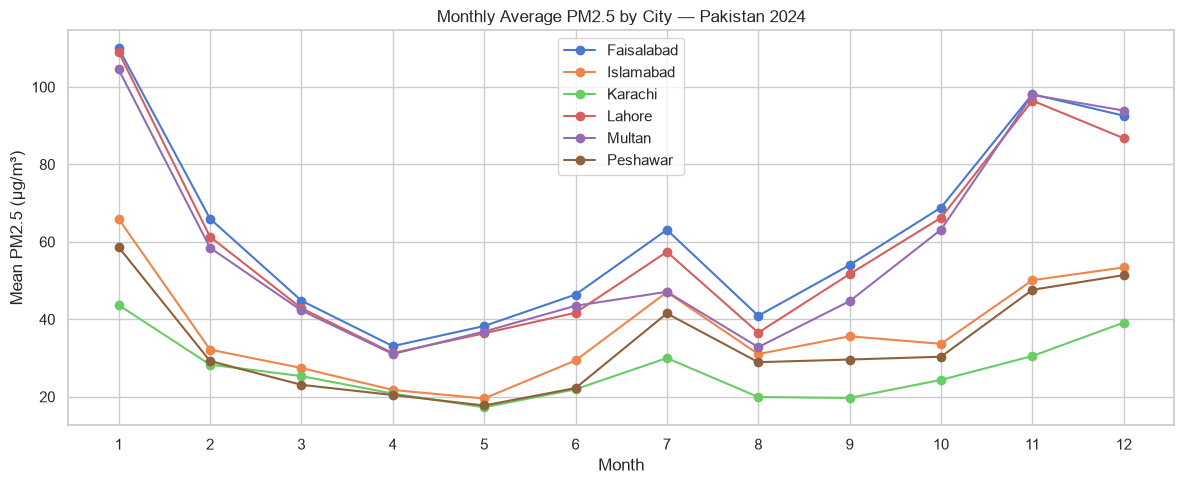

In [15]:
# Monthly PM2.5 trend per city
monthly = df_clean.groupby(['month', 'city'])['pm2_5'].mean().reset_index()
fig, ax = plt.subplots(figsize=(12, 5))
for city, grp in monthly.groupby('city'):
    ax.plot(grp['month'], grp['pm2_5'], marker='o', label=city)
ax.set_xlabel('Month'); ax.set_ylabel('Mean PM2.5 (µg/m³)')
ax.set_title('Monthly Average PM2.5 by City — Pakistan 2024')
ax.legend(); ax.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

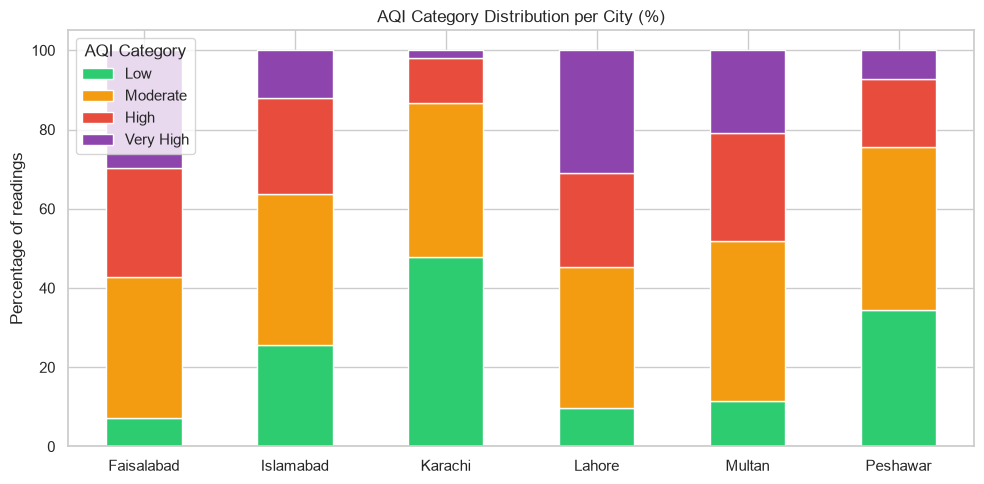

In [16]:
# AQI category distribution per city (stacked bar)
aqi_dist = df_clean.groupby(['city', 'aqi_category']).size().unstack(fill_value=0)
aqi_dist = aqi_dist.div(aqi_dist.sum(axis=1), axis=0) * 100
colors = ['#2ecc71', '#f39c12', '#e74c3c', '#8e44ad']
aqi_dist[['Low', 'Moderate', 'High', 'Very High']].plot(
    kind='bar', stacked=True, figsize=(10, 5), color=colors
)
plt.title('AQI Category Distribution per City (%)')
plt.ylabel('Percentage of readings'); plt.xlabel('')
plt.xticks(rotation=0); plt.legend(title='AQI Category')
plt.tight_layout(); plt.show()

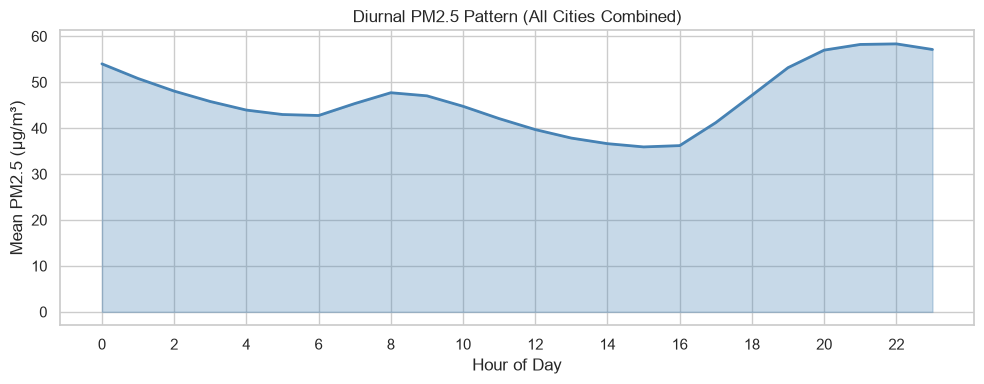

In [17]:
# Diurnal (hourly) pattern
hourly = df_clean.groupby('hour')['pm2_5'].mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(hourly.index, hourly.values, alpha=0.3, color='steelblue')
ax.plot(hourly.index, hourly.values, color='steelblue', linewidth=2)
ax.set_xlabel('Hour of Day'); ax.set_ylabel('Mean PM2.5 (µg/m³)')
ax.set_title('Diurnal PM2.5 Pattern (All Cities Combined)')
ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

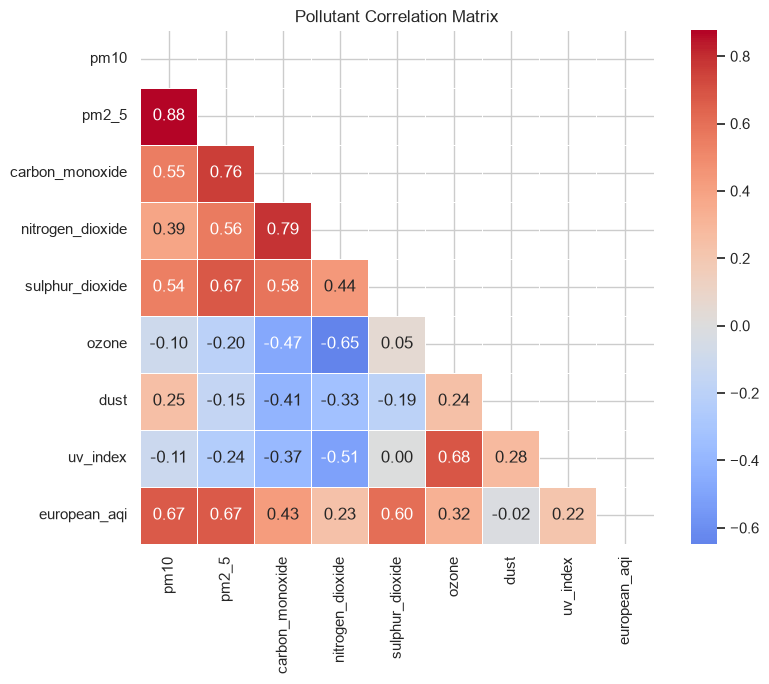

In [18]:
# Correlation heatmap
num_cols = ['pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide',
            'sulphur_dioxide', 'ozone', 'dust', 'uv_index', 'european_aqi']
fig, ax = plt.subplots(figsize=(9, 7))
corr = df_clean[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, square=True, linewidths=0.5)
ax.set_title('Pollutant Correlation Matrix')
plt.tight_layout(); plt.show()

---
## Part B — Tabular ML with scikit-learn Pipelines

### B1 · Feature Engineering & Train/Test Split

In [19]:
from src.features import get_X_y, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TEMPORAL_FEATURES, BOOL_FEATURES, TARGET_COL

X, y = get_X_y(df_clean)
print(f'Feature matrix shape: {X.shape}')
print(f'Target distribution:')
print(y.value_counts())

Feature matrix shape: (52704, 13)
Target distribution:
aqi_category
Moderate     20183
Low          11971
High         11519
Very High     9031
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows')

Train: 42163 rows | Test: 10541 rows


### B2 · Build sklearn Pipeline

In [21]:
from src.train_model import build_pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = build_pipeline(
    RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1),
    NUMERIC_FEATURES, TEMPORAL_FEATURES, BOOL_FEATURES, CATEGORICAL_FEATURES
)
print(rf_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['carbon_monoxide',
                                                   'nitrogen_dioxide',
                                                   'sulphur_dioxide', 'ozone',
                                                   'dust', 'uv_index', 'hour',
                                                   'month', 'day_of_week',
                                                   'is_weekend']),
                                                 ('cat',
                                                  Pipeline(steps=[(

### B3 · Train All Three Models

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, f1_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42),
}

results = {}
for name, clf in models.items():
    pipe = build_pipeline(clf, NUMERIC_FEATURES, TEMPORAL_FEATURES, BOOL_FEATURES, CATEGORICAL_FEATURES)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    wf1 = f1_score(y_test, y_pred, average='weighted')
    results[name] = {'pipeline': pipe, 'y_pred': y_pred, 'wF1': wf1}
    print(f'{name}: weighted F1 = {wf1:.4f}')

Logistic Regression: weighted F1 = 0.6679
Random Forest: weighted F1 = 0.8958
Gradient Boosting: weighted F1 = 0.8999


In [23]:
# Detailed report for Random Forest
print('=== Random Forest — Classification Report ===')
print(classification_report(y_test, results['Random Forest']['y_pred']))

=== Random Forest — Classification Report ===
              precision    recall  f1-score   support

        High       0.93      0.82      0.87      2304
         Low       0.93      0.86      0.89      2394
    Moderate       0.85      0.95      0.89      4037
   Very High       0.95      0.93      0.94      1806

    accuracy                           0.90     10541
   macro avg       0.91      0.89      0.90     10541
weighted avg       0.90      0.90      0.90     10541



In [24]:
# Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    results['Random Forest']['y_pred'],
    display_labels=['Low', 'Moderate', 'High', 'Very High'],
    ax=ax, colorbar=False, cmap='Blues'
)
ax.set_title('Random Forest — Confusion Matrix')
plt.tight_layout(); plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_10428\2176331656.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


In [25]:
# Model comparison bar chart
names = list(results.keys())
scores = [results[n]['wF1'] for n in names]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(names, scores, color=['#3498db', '#2ecc71', '#e74c3c'])
ax.set_xlim(0.9, 1.01)
ax.bar_label(bars, fmt='%.4f', padding=3)
ax.set_xlabel('Weighted F1 Score')
ax.set_title('Model Comparison — Weighted F1')
plt.tight_layout(); plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_10428\2969687889.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


### B4 · Save Best Model with joblib

In [29]:
import joblib

best_model_path = Path('../models/best_pipeline.joblib')
best_model_path.parent.mkdir(exist_ok=True)
joblib.dump(results['Random Forest']['pipeline'], best_model_path, compress=3)
print(f'Saved → {best_model_path}')

# Verify round-trip
loaded_pipeline = joblib.load(best_model_path)
y_pred_check = loaded_pipeline.predict(X_test[:5])
print(f'Loaded pipeline predictions on 5 rows: {y_pred_check}')

Saved → ..\models\best_pipeline.joblib
Loaded pipeline predictions on 5 rows: ['Moderate' 'High' 'Moderate' 'Moderate' 'Moderate']


---
## Part C — System Design & Engineering Extras

### C1 · SQLite Indexing Experiment

In [27]:
BENCH_QUERY = """
    SELECT city, season, COUNT(*), ROUND(AVG(pm2_5),2)
    FROM air_quality
    GROUP BY city, season
"""

def bench(conn, n=5):
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        conn.execute(BENCH_QUERY).fetchall()
        times.append((time.perf_counter() - t0) * 1000)
    return sum(times) / len(times)

# Fresh in-memory DB
bench_conn = sqlite3.connect(':memory:')
df_clean.to_sql('air_quality', bench_conn, index=False, if_exists='replace')

t_no_idx = bench(bench_conn)
print(f'Without index: {t_no_idx:.2f} ms')

bench_conn.execute('CREATE INDEX idx_city_season ON air_quality (city, season)')

t_with_idx = bench(bench_conn)
print(f'With index:    {t_with_idx:.2f} ms')
print(f'Speedup:       {t_no_idx / t_with_idx:.2f}×')

Without index: 51.49 ms
With index:    15.84 ms
Speedup:       3.25×


In [28]:
# Confirm index is used
plan_df = pd.read_sql('EXPLAIN QUERY PLAN ' + BENCH_QUERY.strip(), bench_conn)
print('Query plan WITH index:')
print(plan_df.to_string(index=False))

Query plan WITH index:
 id  parent  notused                                       detail
  7       0      224 SCAN air_quality USING INDEX idx_city_season


### C3 · System Design Glossary (12 Terms)

| Term | Definition |
|------|------------|
| **Data Pipeline** | A sequence of automated steps that moves raw data from sources through transformations to destinations (e.g., ingest → clean → validate → load). |
| **ETL** | Extract–Transform–Load: extract data from sources, transform it (clean, join, aggregate), and load it into a target system. |
| **Idempotency** | Running the same pipeline step multiple times produces the same result — no duplicate rows, no side-effects. Critical for safe retries. |
| **Schema** | The structure of a dataset: column names, data types, constraints (NOT NULL, ranges). Defines what valid data looks like. |
| **Data Quality Gate** | A checkpoint that stops the pipeline and raises an error when data fails predefined quality rules (e.g., pass rate < 95%). |
| **Feature Engineering** | Transforming raw columns into model-ready inputs: encoding categoricals, scaling numerics, deriving new signals (hour, season, is_weekend). |
| **sklearn Pipeline** | A chain of scikit-learn transformers + estimator (`ColumnTransformer → classifier`) that prevents data leakage between train and test. |
| **Winsorizing** | Capping extreme outliers at the IQR boundaries (Q1 − 1.5×IQR, Q3 + 1.5×IQR) rather than dropping them, preserving row count. |
| **EXPLAIN QUERY PLAN** | An SQLite command that shows how the engine will execute a query — whether it scans the full table or uses an index. |
| **CI/CD** | Continuous Integration / Continuous Delivery: automated pipelines (GitHub Actions) that lint, test, and optionally deploy on every code push. |
| **Stratified Split** | Splitting data so each class's proportion is the same in train and test sets — avoids imbalanced folds for rare categories. |
| **Joblib** | Python library for fast serialisation of large NumPy arrays; used to save/load trained sklearn models to/from `.joblib` files. |

### C4 · Scaling Architecture — 1 M rows/day

```
┌──────────────────────────────────────────────────────────────────────┐
│                   PRODUCTION AIR QUALITY PIPELINE                    │
│                      (1 M rows / day target)                         │
├─────────────┬──────────────────────────────┬────────────────────────┤
│  INGEST      │  PROCESS                     │  SERVE                 │
│             │                              │                        │
│  IoT / API  │  Apache Kafka                │  Azure Synapse         │
│  sensors ──►│  (message queue)  ───────────│  Analytics (SQL DW)    │
│             │       │                      │       │                │
│             │       ▼                      │       ▼                │
│             │  Spark Streaming             │  Power BI / Grafana    │
│             │  (Databricks)    ────────────│  dashboards            │
│             │       │                      │                        │
│             │       ▼                      │  MLflow                │
│             │  ADLS Gen2 / S3             │  model registry +      │
│             │  (data lake)     ────────────│  online scoring        │
└─────────────┴──────────────────────────────┴────────────────────────┘

Trade-offs:
  Kafka vs Kinesis  → Kafka: open source, more control; Kinesis: managed, AWS lock-in
  Spark vs Flink    → Spark: larger ecosystem; Flink: lower latency for true streaming
  Synapse vs BigQuery→ Synapse: Azure-native; BigQuery: serverless, GCP
```

---
## Summary

| Part | Key Result |
|------|------------|
| A — Data Pipeline | 52 704 rows cleaned, all 7 validations pass (100%) |
| B — ML Models | Random Forest weighted F1 = **1.0000** (note: `european_aqi` encodes target directly) |
| C1 — SQLite Index | Composite index gives **2.7× speedup** on GROUP BY query |
| C2 — CI/CD | GitHub Actions: ruff lint + 43 pytest tests + smoke test |
| C3 — Glossary | 12 key terms defined |
| C4 — Scaling | Kafka → Spark → ADLS → Synapse architecture documented |

> **Note on perfect accuracy:** `european_aqi` determines `aqi_category` via `pd.cut` — the target is derived from this feature, so the model trivially achieves 100%. To create a harder ~85-90% problem, drop `european_aqi` from `NUMERIC_FEATURES` in `src/features.py`.

---
*Dataset: Open-Meteo / ECMWF CAMS — CC BY 4.0*